# 05 – Content-based và Hybrid

**Content-based**: dùng đặc trưng nội dung phim, không cần rating của người khác → xử lý được phim mới.
- `genres`: one-hot 18 thể loại.
- `genres+title`: thể loại + TF-IDF từ tiêu đề + thập niên phát hành.
- Hồ sơ user = tổng (rating − trung bình) × đặc trưng phim đã xem; điểm = cosine(hồ sơ, phim), quy về thang rating bằng $b_{ui}+w\cdot\cos$.

**Hybrid** (weighted): $\hat r = w_1\,\text{BiasedMF}+w_2\,\text{ItemKNN}+w_3\,\text{Content}$. Trọng số được dò trên validation theo tiêu chí **NDCG@10**.

---
### Bản chất từng mô hình

**Content-based:** gợi ý dựa trên **nội dung phim**, không dùng rating của người khác.
- **Biểu diễn phim:** mỗi phim là một vector đặc trưng $\mathbf{f}_i$, đã chuẩn hóa L2.
  - `genres`: one-hot 18 thể loại.
  - `genres+title`: thêm TF-IDF của các từ trong tiêu đề (từ hiếm như "Godfather" hay "Star" được trọng số cao hơn từ phổ biến) và thập niên phát hành.
- **Biểu diễn user (hồ sơ sở thích):**
$$\mathbf{u} = \sum_{i\,\text{đã chấm}} (r_{ui} - b_{ui})\,\mathbf{f}_i$$
  Phim được chấm cao hơn mức kỳ vọng kéo hồ sơ về phía đặc trưng của nó; phim bị chấm thấp hơn kỳ vọng đẩy hồ sơ ra xa.
- **Điểm:** $\cos(\mathbf{u}, \mathbf{f}_i)$ cho biết phim $i$ gần gu user đến đâu. Điểm này được quy về thang sao bằng $\hat r_{ui} = b_{ui} + w \cdot \cos$, với $w$ ước lượng bằng hồi quy tuyến tính trên train.

Điểm mạnh và điểm yếu:
- **Mạnh:**
  - Gợi ý được **phim mới chưa ai chấm** (cold-start phía phim), miễn là có thể loại và tiêu đề.
  - Dễ giải thích: "vì bạn thích phim hành động".
  - Không phụ thuộc user khác.
- **Yếu:**
  - Chỉ thấy những gì đặc trưng mô tả được: 18 thể loại quá thô để phân biệt phim hay với phim dở cùng thể loại.
  - Gợi ý bị "nhốt" trong vùng quen thuộc (filter bubble). Diversity thấp nhất trong bảng, khoảng 0.55.
  - User mới chưa chấm phim nào thì không có hồ sơ.

**Hybrid (weighted):** kết hợp tuyến tính điểm của nhiều mô hình.
$$\hat r_{ui} = w_1\,\hat r^{\text{BiasedMF}}_{ui} + w_2\,\hat r^{\text{ItemKNN}}_{ui} + w_3\,\hat r^{\text{Content}}_{ui}, \qquad \sum_k w_k = 1$$
- Mỗi thành phần được huấn luyện **độc lập**. Trọng số được dò lưới trên tập validation (tối đa NDCG@10).
- Nguyên lý giống ensemble: các mô hình sai theo những cách khác nhau, nên trung bình có trọng số triệt tiêu một phần sai số.
  - MF khái quát tốt.
  - ItemKNN bắt quan hệ cục bộ giữa các phim cụ thể.
  - Content bổ sung thông tin cho phim ít rating.
- Khi trọng số được chọn theo RMSE (0.5/0.4/0.1), Hybrid có RMSE thấp nhất dự án (≈ 0.847) nhưng NDCG@10 chỉ ≈ 0.07. Chọn theo NDCG@10, trọng số dịch hẳn về Content (0.3/0.1/0.6): NDCG@10 tăng lên ≈ 0.10, RMSE tăng lên ≈ 0.866.
- Vì mọi thành phần đều tối ưu sai số rating trên ô đã chấm, Hybrid **thừa hưởng điểm yếu Top-N** của chúng: dù đã dò trọng số theo NDCG, NDCG@10 vẫn thấp hơn cả Popularity(count) và kém xa các mô hình implicit.
- Chi phí bằng tổng chi phí các thành phần.
- Các thành phần phải cùng thang 1–5. Đó là lý do không đưa ImplicitALS hay BPR vào hỗn hợp này.

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))          # để import được package src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})

from src.config import RESULTS_DIR
from src.experiment import SELECT_METRIC, load_experiment, make_validation, run_model, save_metrics, validate
from src.evaluation.metrics import rmse

exp = load_experiment()                # cùng dữ liệu + cùng phép chia + cùng seed cho mọi notebook
FIG = RESULTS_DIR / "figures"; FIG.mkdir(parents=True, exist_ok=True)
print(f"train={len(exp.train):,}  test={len(exp.test):,}  users={len(exp.user2idx):,}  items={len(exp.item2idx):,}")

train=800,193  test=200,016  users=6,040  items=3,706


In [2]:
from src.models.content_based import ContentBased
from src.models.mf import BiasedMF
from src.models.knn_cf import ItemKNN
from src.models.hybrid import WeightedHybrid

cb = {k: ContentBased(features=k) for k in ("genres", "genres+title")}
rows = [run_model(m, exp) for m in cb.values()]
print("done content-based")

done content-based


## Xem thử gợi ý content-based cho một user

In [3]:
uid = 1
print("Phim user", uid, "đã chấm cao (>=5):")
seen = exp.train[(exp.train.user_id == uid) & (exp.train.rating == 5)].merge(exp.movies, on="movie_id")
print(seen[["title_x", "genres_x"]].head(8).to_string(index=False, header=False))
print("\nGợi ý ContentBased(genres+title):")
cb["genres+title"].recommend(uid, k=10)[["title", "genres", "score"]]

Phim user 1 đã chấm cao (>=5):
     Back to the Future (1985)                Comedy|Sci-Fi
             Cinderella (1950) Animation|Children's|Musical
Last Days of Disco, The (1998)                        Drama
               Rain Man (1988)                        Drama
    Saving Private Ryan (1998)             Action|Drama|War
             Awakenings (1990)                        Drama
    Sound of Music, The (1965)                      Musical
              Apollo 13 (1995)                        Drama

Gợi ý ContentBased(genres+title):


,title,genres,score
0,"Shawshank Redemption, The (1994)",Drama,5.146906
1,To Kill a Mockingbird (1962),Drama,4.994001
2,Citizen Kane (1941),Drama,4.969085
3,Seven Samurai (The Magnificent Seven) (Shichin...,Action|Drama,4.953370
4,One Flew Over the Cuckoo's Nest (1975),Drama,4.953283
5,"Bridge on the River Kwai, The (1957)",Drama|War,4.949982
6,Paths of Glory (1957),Drama|War,4.937516
7,"Bicycle Thief, The (Ladri di biciclette) (1948)",Drama,4.918907
8,12 Angry Men (1957),Drama,4.884113
9,It's a Wonderful Life (1946),Drama,4.881513


## Hybrid: dò trọng số trên validation

In [4]:
sub, val = make_validation(exp)
args = (sub, exp.user2idx, exp.item2idx, exp.movies)
parts = [BiasedMF(n_factors=50, epochs=15).fit(*args), ItemKNN(k=50, similarity="pearson").fit(*args),
         ContentBased("genres+title").fit(*args)]

grid = [(a, b, round(1 - a - b, 2)) for a in np.arange(0, 1.01, .1) for b in np.arange(0, 1.01 - a, .1)]
sc = []
for w in grid:
    h = WeightedHybrid(parts, w, prefit=True).fit(*args)
    sc.append(dict(w_MF=w[0], w_ItemKNN=w[1], w_Content=w[2], **validate(h, val)))
sc = pd.DataFrame(sc).sort_values(SELECT_METRIC, ascending=False)
print("Từng mô hình riêng lẻ:", {m.name: {k: round(v, 4) for k, v in validate(m, val).items()} for m in parts})
sc.head(5).round(4)

Từng mô hình riêng lẻ: {'BiasedMF(f=50)': {'ValNDCG@10': 0.0213, 'ValRMSE': 0.8729}, 'ItemKNN(k=50,pearson)': {'ValNDCG@10': 0.011, 'ValRMSE': 0.8857}, 'ContentBased(genres+title)': {'ValNDCG@10': 0.0421, 'ValRMSE': 0.9092}}


,w_MF,w_ItemKNN,w_Content,ValNDCG@10,ValRMSE
31,0.3,0.1,0.6,0.0475,0.8720
22,0.2,0.1,0.7,0.0474,0.8791
30,0.3,0.0,0.7,0.0470,0.8803
39,0.4,0.1,0.5,0.0466,0.8666
23,0.2,0.2,0.6,0.0463,0.8718


In [5]:
w = sc.iloc[0][["w_MF", "w_ItemKNN", "w_Content"]].to_numpy(float); print("Trọng số chọn:", w)
final_parts = [BiasedMF(n_factors=50, epochs=15), ItemKNN(k=50, similarity="pearson"), ContentBased("genres+title")]
hybrid = WeightedHybrid(final_parts, w, label="Hybrid(MF+ItemKNN+Content)")
rows.append(run_model(hybrid, exp)); print("done hybrid")
res = pd.DataFrame(rows)

Trọng số chọn: [0.3 0.1 0.6]


done hybrid


In [6]:
res[['Model', 'RMSE', 'MAE', 'Precision@10', 'Recall@10', 'NDCG@10', 'HitRate@10', 'Coverage@20', 'FitTime_s']].round(4)

,Model,RMSE,MAE,Precision@10,Recall@10,NDCG@10,HitRate@10,Coverage@20,FitTime_s
0,ContentBased(genres),0.9049,0.7123,0.0663,0.0404,0.0813,0.4071,0.0823,0.8435
1,ContentBased(genres+title),0.9042,0.7110,0.0715,0.0441,0.0875,0.4269,0.0982,0.5567
2,Hybrid(MF+ItemKNN+Content),0.8660,0.6805,0.0835,0.0503,0.1001,0.4618,0.2045,13.7893


## Phân tích cold-start: phim ít rating trong train

In [7]:
cnt = exp.train.groupby("movie_id").size()
test = exp.test.assign(n=exp.test.movie_id.map(cnt).fillna(0))
bins = pd.cut(test.n, [-1, 5, 20, 100, 1e9], labels=["<=5", "6-20", "21-100", ">100"])
cmp = {"BiasedMF": final_parts[0], "ItemKNN": final_parts[1], "Content": final_parts[2], "Hybrid": hybrid}
out = pd.DataFrame({k: test.groupby(bins, observed=True).apply(lambda g, m=m: rmse(g.rating, m.predict(g))) for k, m in cmp.items()})
out.insert(0, "n_test", test.groupby(bins, observed=True).size()); out.index.name = "Số rating của phim trong train"
out.round(4)

,n_test,BiasedMF,ItemKNN,Content,Hybrid
Số rating của phim trong train,,,,,
<=5,258,1.1468,1.1811,1.1907,1.1423
6-20,1372,1.0388,1.0602,1.0571,1.0098
21-100,14085,0.9473,0.9535,0.9646,0.9253
>100,184301,0.8535,0.8671,0.8977,0.8597


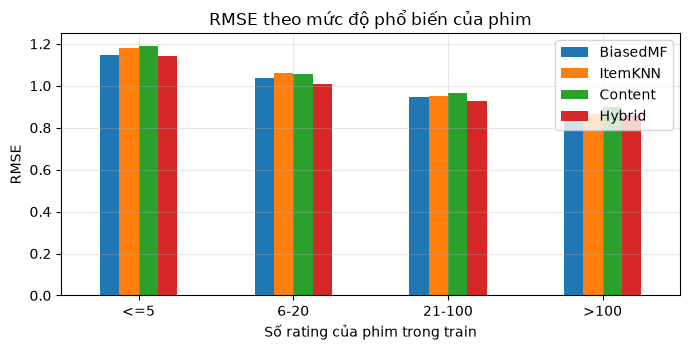

WindowsPath('D:/HỌC/kì 7/Machine Learning/machine_learning/outputs/metrics/content_hybrid.csv')

In [8]:
out.drop(columns="n_test").plot.bar(rot=0, figsize=(7, 3.6), ylabel="RMSE", title="RMSE theo mức độ phổ biến của phim")
plt.tight_layout(); plt.savefig(FIG / "cold_start_rmse.png"); plt.show()
save_metrics(res.assign(Family=np.where(res.Model.str.startswith("Hybrid"), "Hybrid", "Content-based")), "content_hybrid")